# Polynomial Regression
**Unit 4 · Lesson 3 | PV Time Series**  
Instructor: Sepehr Shakibi  
[Applied Machine Learning and Deep Learning for Photovoltaics with Python](https://github.com/SepehrShakibi/applied-ml-dl-for-photovoltaics-with-python)

Predict `target_power_t_plus_1` from measurements at time **t**, using the same prepared partitions as Lesson 2. Following the Polynomial Regression slides, we expand inputs, fit linear regression, compare degrees on validation, and evaluate a fixed model on test.

**Learning goals:** explain why polynomial regression is linear in its coefficients; inspect powers and interactions; use train-fitted pipelines; distinguish underfitting from overfitting; choose complexity without using test data.

## 1. Setup
Run from the project root. `PROJECT_ROOT = os.path.abspath(".")` below assumes that working directory.

**Colab:** runtime storage is temporary. Download outputs or copy them to mounted Drive before the runtime ends. The download command does not automatically mount Drive or relocate downloaded files. Ensure the raw split CSVs are in `data/processed/pv_time_series` before continuing; adjust `data_dir` if your downloaded folder has a different layout.

In [28]:
# %pip install -q numpy pandas matplotlib scikit-learn joblib
%pip install -q gdown

In [29]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib
import sklearn
from IPython.display import display
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OrdinalEncoder, StandardScaler, PolynomialFeatures
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression
from sklearn.dummy import DummyRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

In [30]:
!gdown --folder https://drive.google.com/drive/folders/1lFetK1YgncT5GPdLQFNrkuy8UWf-6881

Retrieving folder contents
Retrieving folder 14T5F5gwA0GGtPapainnN03f1IMhkXgec processed
Retrieving folder 1v372EjkxWn-8UdlhIvcPOS0ohwMXefZE pv_images
Processing file 1RFZRlUEIun3Z36gYpLClX8PRI4Og0Lql pv_images_test.csv
Processing file 1ZAqeFxVdPZu_uqfHT3Q7QRytm1CvbOnU pv_images_train.csv
Processing file 1pW98UOlS7Mh4LKHooN_1pzJjetJCnQFg pv_images_unknown.csv
Processing file 1hkMI_UN5FwmoSOfSXNuhz2zngOEjO-7k pv_images_validation.csv
Retrieving folder 1z994qLWlxE0mszwY1rLm8_1wQaso5gDB pv_time_series
Processing file 1DKNF0q9QHGBQSywBeNCC37bCEexxyWFq column_mapping.csv
Processing file 1bJlRxrYgcVEA1u383vq-F5g7E_lUQW3A pv_time_series_preprocessing.joblib
Processing file 1H5WyuYLz-Hye9SERAy1O3pu4grXmtLcJ pv_time_series_test_encoded.csv
Processing file 1ErXBDQHcCYa3aFv8rL0u7GTJkutuY5On pv_time_series_test_standardized.csv
Processing file 1IB0qv5K87J6MGmc8Q7SG-Q0lC745In1r pv_time_series_test.csv
Processing file 1nHbXSH4AxfpEwkwcqBfWOQVOI96SGaZQ pv_time_series_train_encoded.csv
Processing file

In [31]:
PROJECT_ROOT = os.path.abspath(".")
CONFIG = {
    "data_dir": os.path.join(PROJECT_ROOT, "data", "processed", "pv_time_series"),
    "output_dir": os.path.join(PROJECT_ROOT, "outputs", "04_03_polynomial_regression"),
}

## 2. Load the prepared data
Read the **raw, unscaled** split CSVs from Unit 3—not the `_encoded` or `_standardized` versions. The target and chronological partitions already exist. Do not split again, shift labels again, or repeat EDA and cleaning.

In [32]:
train_data = pd.read_csv(os.path.join(CONFIG["data_dir"], "pv_time_series_train.csv"))
validation_data = pd.read_csv(os.path.join(CONFIG["data_dir"], "pv_time_series_validation.csv"))
test_data = pd.read_csv(os.path.join(CONFIG["data_dir"], "pv_time_series_test.csv"))

print("Train:", train_data.shape)
print("Validation:", validation_data.shape)
print("Test:", test_data.shape)
display(train_data.head())

Train: (4955, 25)
Validation: (1061, 25)
Test: (1061, 25)


,day,cosine_of_day,hour,cosine_of_hour,air_temperature,dewpoint,wind_speed,air_pressure,weather_condition,solar_radiation,...,pv_3_power,pv_4_cosine_value_of_the_solar_incidence_angle,pv_4_power,pv_5_cosine_value_of_the_solar_incidence_angle,pv_5_power,total_pv_power,time_index,target_time_index,target_power_t_plus_1,target_class_t_plus_1
0,1,0.999852,1,1.0000,2,81,6,900.2,10,0.0,...,0,0.0,0,0.0,0,0,0,1,0.0,low
1,1,0.999852,2,0.9659,-1,86,0,900.2,10,0.0,...,0,0.0,0,0.0,0,0,1,2,0.0,low
2,1,0.999852,3,0.8660,0,87,6,900.2,10,0.0,...,0,0.0,0,0.0,0,0,2,3,0.0,low
3,1,0.999852,4,0.7071,-1,86,2,900.2,10,0.0,...,0,0.0,0,0.0,0,0,3,4,0.0,low
4,1,0.999852,5,0.5000,-1,86,6,900.2,10,0.0,...,0,0.0,0,0.0,0,0,4,5,0.0,low


## 3. Select inputs and target
Use an explicit list so neither future target enters the inputs. Time metadata stays outside the model. Exclude current `total_pv_power` from the inputs because the five panel powers already contain its sum; keep it as the persistence baseline.

All inputs must be available at forecast time. Confirm the definition and availability of `dewpoint` before operational use.

In [33]:
TARGET = "target_power_t_plus_1"
NUMERIC_FEATURES = [
    "cosine_of_day", "cosine_of_hour", "air_temperature", "dewpoint",
    "wind_speed", "air_pressure", "solar_radiation",
    "pv_1_cosine_value_of_the_solar_incidence_angle", "pv_1_power",
    "pv_2_cosine_value_of_the_solar_incidence_angle", "pv_2_power",
    "pv_3_cosine_value_of_the_solar_incidence_angle", "pv_3_power",
    "pv_4_cosine_value_of_the_solar_incidence_angle", "pv_4_power",
    "pv_5_cosine_value_of_the_solar_incidence_angle", "pv_5_power",
]
CATEGORICAL_FEATURES = ["weather_condition"]
FEATURES = NUMERIC_FEATURES + CATEGORICAL_FEATURES

X_train = train_data[FEATURES]
y_train = train_data[TARGET]
X_validation = validation_data[FEATURES]
y_validation = validation_data[TARGET]
X_test = test_data[FEATURES]
y_test = test_data[TARGET]

print("Number of inputs:", len(FEATURES))

Number of inputs: 18


## 4. From straight lines to polynomial features
For one input, a degree-3 model is
\[
\hat y=b_0+b_1x+b_2x^2+b_3x^3.
\]
The relationship can curve in **x**, but remains linear in the learned coefficients. We still use `LinearRegression`, a direct least-squares solver: there is no learning rate or epoch count.

With two inputs and degree 2, the expanded inputs are $x_1,x_2,x_1^2,x_1x_2,x_2^2$. `PolynomialFeatures` creates both powers and interactions, not just each column's square. `include_bias=False` avoids a constant feature because the regressor already fits an intercept.

The tiny example below illustrates the transformation only; it is not PV data and does not fit the forecasting model.

In [34]:
example_inputs = pd.DataFrame({"x1": [2.0, 3.0], "x2": [4.0, 5.0]})
example_polynomial = PolynomialFeatures(degree=2, include_bias=False)
example_expanded = example_polynomial.fit_transform(example_inputs)
display(pd.DataFrame(
    example_expanded,
    columns=example_polynomial.get_feature_names_out(),
))

,x1,x2,x1^2,x1 x2,x2^2
0,2.0,4.0,4.0,8.0,16.0
1,3.0,5.0,9.0,15.0,25.0


## 5. Train-only preprocessing and model pipelines
For each candidate:
1. Expand **numeric measurements only** to the chosen degree.
2. Ordinal-encode weather, as in Lesson 2, as a separate branch.
3. Standardize all resulting columns with training statistics.
4. Fit `LinearRegression` on the training target.

We deliberately do **not** square weather codes or create weather interactions: these codes are arbitrary category labels, not physical measurements. Even a linear ordinal effect imposes artificial order and distances; one-hot encoding is an alternative for a later experiment. Unseen weather categories receive code `-1`.

Every candidate has its own explicitly constructed pipeline. Fit only on train; prediction reuses fitted transformations. Do not load the Unit 3 scaler or pre-encoded CSVs. Polynomial expansion learns no distribution statistics, but belongs inside the pipeline for consistent transformation.

**Only X is scaled:** predictions and metrics remain in original target units, whose physical unit has not been confirmed. No inverse scaling of y is needed.

Degree 1 is the linear reference. Degrees 2 and 3 add flexibility, not new information. For 17 numerical inputs, these create 17, 170 and 1,139 numeric terms respectively, plus one weather column. Larger degrees quickly increase memory, fitting cost, collinearity and extrapolation risk. Scaling helps numerical conditioning but does not eliminate these problems.

In [35]:
linear_pipeline = Pipeline([
    ("features", ColumnTransformer([
        ("numeric", PolynomialFeatures(
            degree=1, include_bias=False,
        ), NUMERIC_FEATURES),
        ("weather", OrdinalEncoder(
            handle_unknown="use_encoded_value", unknown_value=-1,
        ), CATEGORICAL_FEATURES),
    ])),
    ("scaler", StandardScaler()),
    ("regressor", LinearRegression()),
])

linear_pipeline.fit(X_train, y_train)
print("Degree 1 — expanded inputs:", linear_pipeline.named_steps["scaler"].n_features_in_)
print("Design matrix rank:", linear_pipeline.named_steps["regressor"].rank_)

Degree 1 — expanded inputs: 18
Design matrix rank: 18


In [36]:
quadratic_pipeline = Pipeline([
    ("features", ColumnTransformer([
        ("numeric", PolynomialFeatures(
            degree=2, include_bias=False,
        ), NUMERIC_FEATURES),
        ("weather", OrdinalEncoder(
            handle_unknown="use_encoded_value", unknown_value=-1,
        ), CATEGORICAL_FEATURES),
    ])),
    ("scaler", StandardScaler()),
    ("regressor", LinearRegression()),
])

quadratic_pipeline.fit(X_train, y_train)
print("Degree 2 — expanded inputs:", quadratic_pipeline.named_steps["scaler"].n_features_in_)
print("Design matrix rank:", quadratic_pipeline.named_steps["regressor"].rank_)

Degree 2 — expanded inputs: 171
Design matrix rank: 171


In [37]:
cubic_pipeline = Pipeline([
    ("features", ColumnTransformer([
        ("numeric", PolynomialFeatures(
            degree=3, include_bias=False,
        ), NUMERIC_FEATURES),
        ("weather", OrdinalEncoder(
            handle_unknown="use_encoded_value", unknown_value=-1,
        ), CATEGORICAL_FEATURES),
    ])),
    ("scaler", StandardScaler()),
    ("regressor", LinearRegression()),
])

cubic_pipeline.fit(X_train, y_train)
print("Degree 3 — expanded inputs:", cubic_pipeline.named_steps["scaler"].n_features_in_)
print("Design matrix rank:", cubic_pipeline.named_steps["regressor"].rank_)

Degree 3 — expanded inputs: 1140
Design matrix rank: 1103


## 6. Baselines and validation evaluation
Use the same training-mean and persistence baselines as Lesson 2. Persistence forecasts next-step power using current `total_pv_power`.

MAE and RMSE use original target units; MSE uses squared units. Lower is better. R² is higher-is-better and can be negative. Evaluate each model separately before assembling the comparison table.

In [38]:
mean_regressor = DummyRegressor(strategy="mean")
mean_regressor.fit(X_train, y_train)

mean_validation_prediction = mean_regressor.predict(X_validation)
mean_mae = mean_absolute_error(y_validation, mean_validation_prediction)
mean_mse = mean_squared_error(y_validation, mean_validation_prediction)
mean_rmse = np.sqrt(mean_mse)
mean_r2 = r2_score(y_validation, mean_validation_prediction)

print("Training mean")
print("MAE:", mean_mae)
print("MSE:", mean_mse)
print("RMSE:", mean_rmse)
print("R2:", mean_r2)

Training mean
MAE: 378.9767264475472
MSE: 200281.1509858138
RMSE: 447.5278214656758
R2: -0.02150109216213436


In [39]:
persistence_validation_prediction = validation_data["total_pv_power"].to_numpy()
persistence_mae = mean_absolute_error(y_validation, persistence_validation_prediction)
persistence_mse = mean_squared_error(y_validation, persistence_validation_prediction)
persistence_rmse = np.sqrt(persistence_mse)
persistence_r2 = r2_score(y_validation, persistence_validation_prediction)

print("Persistence")
print("MAE:", persistence_mae)
print("MSE:", persistence_mse)
print("RMSE:", persistence_rmse)
print("R2:", persistence_r2)

Persistence
MAE: 99.97360980207351
MSE: 26801.80395852969
RMSE: 163.71256506001515
R2: 0.863301804084935


In [40]:
linear_validation_prediction = linear_pipeline.predict(X_validation)
linear_mae = mean_absolute_error(y_validation, linear_validation_prediction)
linear_mse = mean_squared_error(y_validation, linear_validation_prediction)
linear_rmse = np.sqrt(linear_mse)
linear_r2 = r2_score(y_validation, linear_validation_prediction)

print("Degree 1")
print("MAE:", linear_mae)
print("MSE:", linear_mse)
print("RMSE:", linear_rmse)
print("R2:", linear_r2)

Degree 1
MAE: 56.01924635268806
MSE: 8091.40255741926
RMSE: 89.95222374916176
R2: 0.9587311311681412


In [41]:
quadratic_validation_prediction = quadratic_pipeline.predict(X_validation)
quadratic_mae = mean_absolute_error(y_validation, quadratic_validation_prediction)
quadratic_mse = mean_squared_error(y_validation, quadratic_validation_prediction)
quadratic_rmse = np.sqrt(quadratic_mse)
quadratic_r2 = r2_score(y_validation, quadratic_validation_prediction)

print("Degree 2")
print("MAE:", quadratic_mae)
print("MSE:", quadratic_mse)
print("RMSE:", quadratic_rmse)
print("R2:", quadratic_r2)

Degree 2
MAE: 50.01994884222064
MSE: 7231.811924714137
RMSE: 85.04006070502382
R2: 0.9631153319069456


In [42]:
cubic_validation_prediction = cubic_pipeline.predict(X_validation)
cubic_mae = mean_absolute_error(y_validation, cubic_validation_prediction)
cubic_mse = mean_squared_error(y_validation, cubic_validation_prediction)
cubic_rmse = np.sqrt(cubic_mse)
cubic_r2 = r2_score(y_validation, cubic_validation_prediction)

print("Degree 3")
print("MAE:", cubic_mae)
print("MSE:", cubic_mse)
print("RMSE:", cubic_rmse)
print("R2:", cubic_r2)

Degree 3
MAE: 373.7860299276545
MSE: 1647530.3120016144
RMSE: 1283.5615731244116
R2: -7.402957566381657


In [43]:
validation_results = pd.DataFrame({
    "Model": ["Training mean", "Persistence", "Degree 1", "Degree 2", "Degree 3"],
    "MAE": [mean_mae, persistence_mae, linear_mae, quadratic_mae, cubic_mae],
    "MSE": [mean_mse, persistence_mse, linear_mse, quadratic_mse, cubic_mse],
    "RMSE": [mean_rmse, persistence_rmse, linear_rmse, quadratic_rmse, cubic_rmse],
    "R2": [mean_r2, persistence_r2, linear_r2, quadratic_r2, cubic_r2],
})
display(validation_results)

,Model,MAE,MSE,RMSE,R2
0,Training mean,378.976726,2.002812e+05,447.527821,-0.021501
1,Persistence,99.973610,2.680180e+04,163.712565,0.863302
2,Degree 1,56.019246,8.091403e+03,89.952224,0.958731
3,Degree 2,50.019949,7.231812e+03,85.040061,0.963115
4,Degree 3,373.786030,1.647530e+06,1283.561573,-7.402958


## 7. Degree, underfitting and overfitting
Compare train and validation error against **degree**, not epochs. The fitted least-squares models do not need more epochs. If degree 1 is too restrictive, training longer will not add curvature.

Low training error with substantially worse validation error suggests overfitting or temporal distribution change. High error on both sets may suggest underfitting, weak inputs or irreducible uncertainty. A higher degree is not guaranteed to improve forecasting. In exact arithmetic the nested polynomial models cannot increase the optimal training squared error; numerical conditioning can complicate this in practice.

Do not assume that degree 2 wins just because a slide shows a quadratic curve. Prefer a simpler degree when validation performance is similar, and compare against persistence.

,degree,train_rmse,validation_rmse
0,1,117.375625,89.952224
1,2,98.717272,85.040061
2,3,71.923473,1283.561573


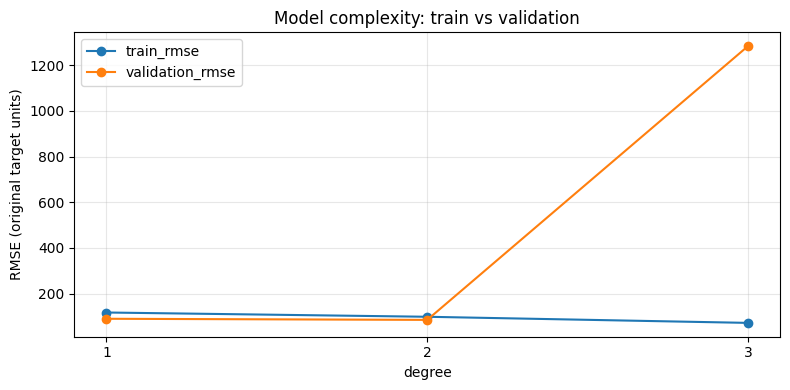

In [44]:
linear_train_prediction = linear_pipeline.predict(X_train)
quadratic_train_prediction = quadratic_pipeline.predict(X_train)
cubic_train_prediction = cubic_pipeline.predict(X_train)

linear_train_rmse = np.sqrt(mean_squared_error(y_train, linear_train_prediction))
quadratic_train_rmse = np.sqrt(mean_squared_error(y_train, quadratic_train_prediction))
cubic_train_rmse = np.sqrt(mean_squared_error(y_train, cubic_train_prediction))

degree_results = pd.DataFrame({
    "degree": [1, 2, 3],
    "train_rmse": [linear_train_rmse, quadratic_train_rmse, cubic_train_rmse],
    "validation_rmse": [linear_rmse, quadratic_rmse, cubic_rmse],
})
display(degree_results)
ax = degree_results.plot(x="degree", y=["train_rmse", "validation_rmse"], marker="o", figsize=(8, 4))
ax.set(xticks=[1, 2, 3], ylabel="RMSE (original target units)", title="Model complexity: train vs validation")
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

### Explicit choice before opening the test results
Review validation metrics and the error analysis below, then record your choice and reasoning. The assignment below uses **degree 2 as a teaching default**, not a claim that it is best on this dataset. Change both assignments to degree 1 or degree 3 if justified by validation. There is no automatic model selection.

Keep this train-fitted pipeline unchanged for the final test and saved artifact. Do not refit on train + validation in this lesson.

In [45]:
chosen_pipeline = quadratic_pipeline
chosen_degree = 2
# Before the final test, explain your validation-based decision here.
selection_reason = "Teaching default: degree 2; replace with your validation-based justification."
print("Chosen degree:", chosen_degree)
print(selection_reason)

Chosen degree: 2
Teaching default: degree 2; replace with your validation-based justification.


## 8. Coefficients of the chosen polynomial model
Names identify powers and interactions of the original numeric inputs. Coefficients multiply **standardized expanded terms**, not raw measurements. Each coefficient describes a change in a term holding the other terms fixed, but powers and interactions cannot generally be varied independently. Consequently, these are not standalone physical effects or causal feature importances. The slope with respect to an original input depends on its value and other interacting inputs.

Inspect the full table; plot only the 20 largest absolute coefficients for readability. Correlated terms can make coefficients unstable.

,feature,coefficient
0,numeric__cosine_of_day,937.663415
1,numeric__cosine_of_hour,815.493711
2,numeric__air_temperature,298.977497
3,numeric__dewpoint,-986.371811
4,numeric__wind_speed,67.502106
...,...,...
166,numeric__pv_4_power pv_5_power,385.332989
167,numeric__pv_5_cosine_value_of_the_solar_incide...,-1485.206676
168,numeric__pv_5_cosine_value_of_the_solar_incide...,4021.621613
169,numeric__pv_5_power^2,-283.798853


Intercept: 282.63391726711166


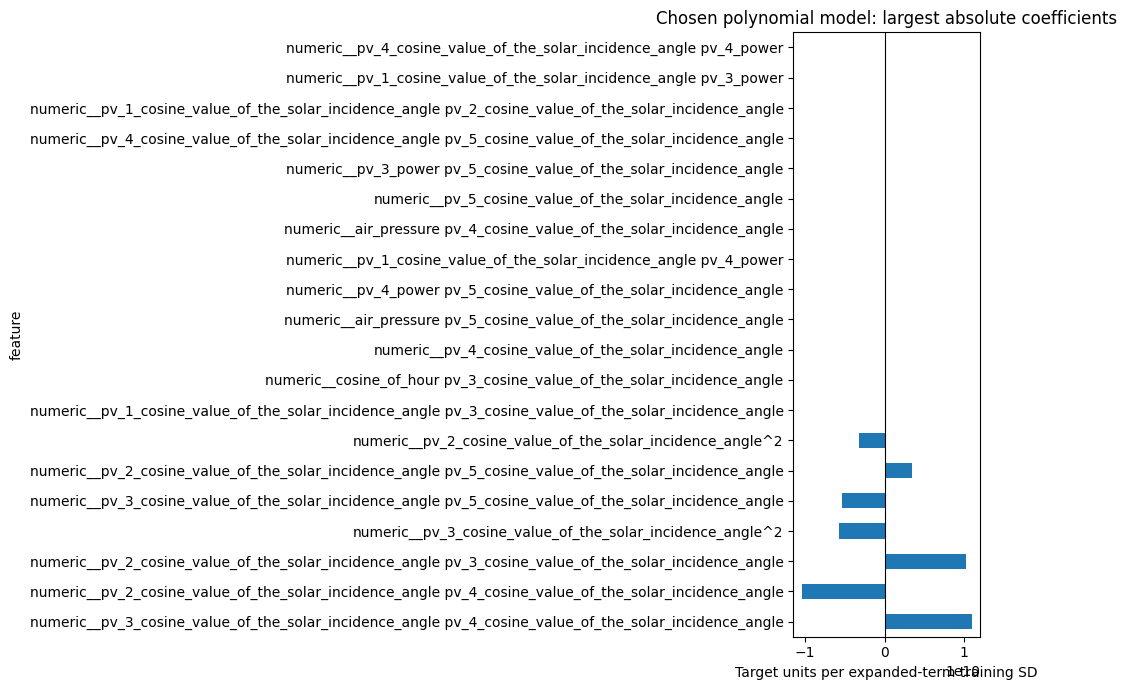

In [46]:
feature_names = chosen_pipeline.named_steps["features"].get_feature_names_out()
coefficients = pd.DataFrame({
    "feature": feature_names,
    "coefficient": chosen_pipeline.named_steps["regressor"].coef_,
})
display(coefficients)
print("Intercept:", chosen_pipeline.named_steps["regressor"].intercept_)
largest_indices = coefficients["coefficient"].abs().nlargest(20).index
ax = coefficients.loc[largest_indices].set_index("feature")["coefficient"].plot.barh(figsize=(10, 7))
ax.axvline(0, color="black", linewidth=0.8)
ax.set(title="Chosen polynomial model: largest absolute coefficients", xlabel="Target units per expanded-term training SD")
plt.tight_layout()
plt.show()

## 9. Validation error analysis
Residual = actual − predicted; positive values indicate underprediction. Look for curvature, changing spread and temporal patterns. These are validation diagnostics, not a reason to inspect test repeatedly. Polynomial extrapolation can become extreme outside the training range. Do not silently clip negative forecasts.

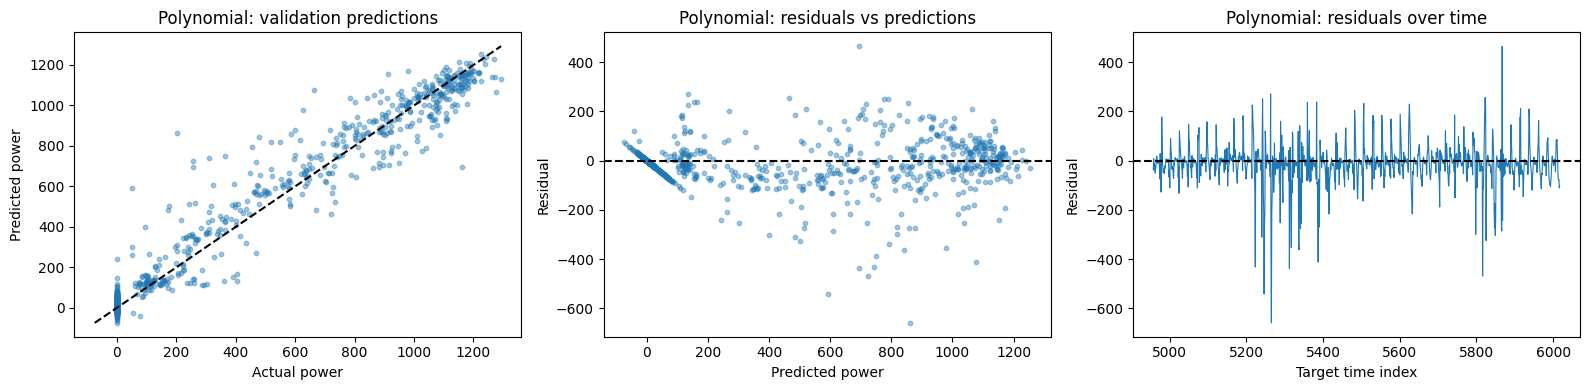

Negative validation predictions: 189


In [47]:
chosen_validation_prediction = chosen_pipeline.predict(X_validation)

chosen_validation_residual = (
    y_validation.to_numpy() - chosen_validation_prediction
)

fig, axes = plt.subplots(1, 3, figsize=(16, 4))

# Actual vs predicted
axes[0].scatter(
    y_validation,
    chosen_validation_prediction,
    s=10,
    alpha=0.4,
)

low = min(y_validation.min(), chosen_validation_prediction.min())
high = max(y_validation.max(), chosen_validation_prediction.max())

axes[0].plot([low, high], [low, high], "k--")
axes[0].set(
    xlabel="Actual power",
    ylabel="Predicted power",
    title="Polynomial: validation predictions",
)

# Residuals vs predicted
axes[1].scatter(
    chosen_validation_prediction,
    chosen_validation_residual,
    s=10,
    alpha=0.4,
)
axes[1].axhline(0, color="black", linestyle="--")
axes[1].set(
    xlabel="Predicted power",
    ylabel="Residual",
    title="Polynomial: residuals vs predictions",
)

# Residuals over time
axes[2].plot(
    validation_data["target_time_index"],
    chosen_validation_residual,
    linewidth=0.8,
)
axes[2].axhline(0, color="black", linestyle="--")
axes[2].set(
    xlabel="Target time index",
    ylabel="Residual",
    title="Polynomial: residuals over time",
)

plt.tight_layout()
plt.show()

print(
    "Negative validation predictions:",
    int((chosen_validation_prediction < 0).sum()),
)

## 10. Final test evaluation
**Stop here until the choice is fixed using validation.** Evaluate the chosen model, degree-1 reference, training mean and persistence once. Do not choose a different degree based on test. Test errors support this chronological forecasting setup, not transfer to unseen PV systems.

In [48]:
mean_test_prediction = mean_regressor.predict(X_test)
mean_test_mae = mean_absolute_error(y_test, mean_test_prediction)
mean_test_mse = mean_squared_error(y_test, mean_test_prediction)
mean_test_rmse = np.sqrt(mean_test_mse)
mean_test_r2 = r2_score(y_test, mean_test_prediction)

print("Mean — Test")
print("MAE:", mean_test_mae)
print("MSE:", mean_test_mse)
print("RMSE:", mean_test_rmse)
print("R2:", mean_test_r2)

Mean — Test
MAE: 365.30138408732313
MSE: 188472.9895030628
RMSE: 434.1347596116473
R2: -0.002314937918678872


In [49]:
persistence_test_prediction = test_data["total_pv_power"].to_numpy()
persistence_test_mae = mean_absolute_error(y_test, persistence_test_prediction)
persistence_test_mse = mean_squared_error(y_test, persistence_test_prediction)
persistence_test_rmse = np.sqrt(persistence_test_mse)
persistence_test_r2 = r2_score(y_test, persistence_test_prediction)

print("Persistence — Test")
print("MAE:", persistence_test_mae)
print("MSE:", persistence_test_mse)
print("RMSE:", persistence_test_rmse)
print("R2:", persistence_test_r2)

Persistence — Test
MAE: 97.01225259189444
MSE: 30167.681432610745
RMSE: 173.68846085048582
R2: 0.8395657763905403


In [50]:
linear_test_prediction = linear_pipeline.predict(X_test)
linear_test_mae = mean_absolute_error(y_test, linear_test_prediction)
linear_test_mse = mean_squared_error(y_test, linear_test_prediction)
linear_test_rmse = np.sqrt(linear_test_mse)
linear_test_r2 = r2_score(y_test, linear_test_prediction)

print("Linear — Test")
print("MAE:", linear_test_mae)
print("MSE:", linear_test_mse)
print("RMSE:", linear_test_rmse)
print("R2:", linear_test_r2)

Linear — Test
MAE: 81.05917687938909
MSE: 16370.089084761574
RMSE: 127.9456489481435
R2: 0.9129425130466804


In [51]:
chosen_test_prediction = chosen_pipeline.predict(X_test)
chosen_test_mae = mean_absolute_error(y_test, chosen_test_prediction)
chosen_test_mse = mean_squared_error(y_test, chosen_test_prediction)
chosen_test_rmse = np.sqrt(chosen_test_mse)
chosen_test_r2 = r2_score(y_test, chosen_test_prediction)

print("Chosen — Test")
print("MAE:", chosen_test_mae)
print("MSE:", chosen_test_mse)
print("RMSE:", chosen_test_rmse)
print("R2:", chosen_test_r2)

Chosen — Test
MAE: 82.4728881975417
MSE: 20579.17246201119
RMSE: 143.45442642878325
R2: 0.8905582597110376


In [52]:
test_results = pd.DataFrame({
    "Model": ["Training mean", "Persistence", "Degree 1", f"Chosen degree {chosen_degree}"],
    "MAE": [mean_test_mae, persistence_test_mae, linear_test_mae, chosen_test_mae],
    "MSE": [mean_test_mse, persistence_test_mse, linear_test_mse, chosen_test_mse],
    "RMSE": [mean_test_rmse, persistence_test_rmse, linear_test_rmse, chosen_test_rmse],
    "R2": [mean_test_r2, persistence_test_r2, linear_test_r2, chosen_test_r2],
})
display(test_results)

,Model,MAE,MSE,RMSE,R2
0,Training mean,365.301384,188472.989503,434.134760,-0.002315
1,Persistence,97.012253,30167.681433,173.688461,0.839566
2,Degree 1,81.059177,16370.089085,127.945649,0.912943
3,Chosen degree 2,82.472888,20579.172462,143.454426,0.890558


In [53]:
prediction_table = test_data[["time_index", "target_time_index", TARGET]].copy()
prediction_table["mean_prediction"] = mean_test_prediction
prediction_table["persistence_prediction"] = persistence_test_prediction
prediction_table["linear_prediction"] = linear_test_prediction
prediction_table["chosen_prediction"] = chosen_test_prediction
prediction_table["chosen_residual"] = y_test.to_numpy() - chosen_test_prediction
display(prediction_table.head(10))

,time_index,target_time_index,target_power_t_plus_1,mean_prediction,persistence_prediction,linear_prediction,chosen_prediction,chosen_residual
0,6018,6019,0.0,282.633905,0,10.770475,44.553971,-44.553971
1,6019,6020,0.0,282.633905,0,9.681124,7.599204,-7.599204
2,6020,6021,0.0,282.633905,0,-1.044103,-16.140664,16.140664
3,6021,6022,0.0,282.633905,0,-8.079068,-16.222626,16.222626
4,6022,6023,0.0,282.633905,0,-20.952206,-7.267847,7.267847
5,6023,6024,0.0,282.633905,0,-30.904484,5.253980,-5.253980
6,6024,6025,0.0,282.633905,0,-34.793456,10.351299,-10.351299
7,6025,6026,0.0,282.633905,0,-24.495759,5.994320,-5.994320
8,6026,6027,0.0,282.633905,0,-9.998840,-1.465602,1.465602
9,6027,6028,0.0,282.633905,0,1.437958,-6.902033,6.902033


## 11. Save the complete pipeline and reuse it
The artifact includes polynomial expansion, weather encoding, scaling and regression. Supply **raw, unencoded, unscaled** feature rows in the same schema. Do not manually expand or scale them again.

Only lesson outputs are written; source CSVs are unchanged. Rerunning replaces lesson artifacts. Load only trusted joblib files, and keep compatible library versions. In Colab, copy these artifacts to persistent storage before disconnecting.

In [54]:
os.makedirs(CONFIG["output_dir"], exist_ok=True)
model_path = os.path.join(CONFIG["output_dir"], "polynomial_regression_pipeline.joblib")
artifact = {
    "pipeline": chosen_pipeline,
    "degree": chosen_degree,
    "selection_reason": selection_reason,
    "feature_columns": FEATURES,
    "target_column": TARGET,
    "input_format": "raw, unencoded, unscaled features",
    "polynomial_scope": "numeric features only",
    "target_scaled": False,
    "config": CONFIG,
    "versions": {"scikit_learn": sklearn.__version__, "pandas": pd.__version__, "numpy": np.__version__},
}
joblib.dump(artifact, model_path)
validation_results.to_csv(os.path.join(CONFIG["output_dir"], "validation_metrics.csv"), index=False)
degree_results.to_csv(os.path.join(CONFIG["output_dir"], "degree_comparison.csv"), index=False)
test_results.to_csv(os.path.join(CONFIG["output_dir"], "test_metrics.csv"), index=False)
prediction_table.to_csv(os.path.join(CONFIG["output_dir"], "test_predictions.csv"), index=False)
coefficients.to_csv(os.path.join(CONFIG["output_dir"], "coefficients.csv"), index=False)

loaded_artifact = joblib.load(model_path)
new_observations = test_data.loc[:, loaded_artifact["feature_columns"]].head(5)
new_predictions = loaded_artifact["pipeline"].predict(new_observations)
np.testing.assert_allclose(new_predictions, chosen_test_prediction[:5])
print("Reload check passed. Predictions in original target units:")
print(new_predictions)
print("Saved to:", CONFIG["output_dir"])

Reload check passed. Predictions in original target units:
[ 44.55397078   7.59920355 -16.14066366 -16.22262624  -7.26784662]
Saved to: /content/outputs/04_03_polynomial_regression


## 12. Summary
- Polynomial regression is nonlinear in the inputs but linear in its coefficients.
- Expansion creates powers and interactions; the number of terms grows quickly.
- Encoding, expansion, scaling and regression belong to one train-fitted pipeline.
- Degree controls flexibility; validation, not training error or test, guides the choice.
- More complex models can overfit, extrapolate poorly and still lose to persistence.
- Only X was scaled, so prediction and evaluation need no inverse target transform.
- Future temporal cross-validation must refit the entire pipeline in each training fold.

**Practice (use validation only):**
1. Write out the degree-2 terms for two numeric inputs and explain `include_bias=False`.
2. Explain the train–validation error gap for each degree without assuming the most complex model wins.
3. Justify your chosen degree and compare it with persistence.
4. Explain why squaring an arbitrary weather code would be misleading.
5. Explain why an underfit direct least-squares model is not fixed by “more training”.

**Reference:** accompanying *Unit 4 · Lesson 3: Polynomial Regression* slides. No new cleaning, chronological splitting or target construction is performed here.